# GAN on synthetic data

This notebook trains the original GAN: a generator and a discriminator trained against each other, one time step at a time.

**Data:** 500 points of f(x) = (x − 3.5)³ + 0.9·cos(2x) + ε on [0, 8], with ε ~ N(−2, 3), normalised. A noisy series with a clear trend.

The architecture and hyperparameters below were found beforehand by optimisation (Metropolis-Hastings search, then Optuna). The last section shows how. Here we train the model with that configuration, compare generated and real data, and evaluate it.

Run this notebook from the repository root, with `data/synthetic_data.csv` in place (the datasets are not distributed with the repository).

## Setup

In [1]:
import random

import numpy as np
import pandas as pd
import torch

from time_series_gan import GAN
from time_series_gan.metrics import dWasserstein, dFrechet, ONND, score

# Fix random seeds so the outputs below can be reproduced
random.seed(0)
np.random.seed(0)
torch.manual_seed(0);

## Data

In [2]:
data = pd.read_csv("data/synthetic_data.csv")
print(f"{data.shape[0]} rows, {data.shape[1]} column(s)")
data.head()

500 rows, 1 column(s)


,Synthetic Data
0,-1.921430
1,-1.839605
2,-1.967728
3,-1.856667
4,-1.950187


## Optimised configuration

Found by `results_pkl/optimised_architectures.txt`. `layer_sizes` lists the size of each hidden layer; the last value is the output size.

In [3]:
params = {
    'lr_g': 0.0005932,
    'lr_d': 0.0514,
    'epochs': 40,
    'batch_size': 3,
    'latent_dim': 1,
}

archi = {
    'generator': {'architecture': 'MLP', 'layer_sizes': [78, 15, 20, 1]},
    'discriminator': {'architecture': 'MLP', 'layer_sizes': [70, 1]},
}

## Training

`fit` returns the metrics chosen with `set_metrics`, as (train value, validation value). Lower is better.

In [4]:
model = GAN()
model.set_data(data)
model.set_metrics({
    'dWasserstein': {'function': dWasserstein, 'metric_args': {}},
    'dFrechet': {'function': dFrechet, 'metric_args': {}},
    'ONND': {'function': ONND, 'metric_args': {}},
    'score': {'function': score, 'metric_args': {}},
})
results = model.fit(params=params, architectures=archi)
pd.DataFrame(results, index=['train', 'validation']).round(3)

fit took 7.647230 seconds


,dWasserstein,dFrechet,ONND,score
train,0.097,1.693,0.007,1.832
validation,0.305,1.893,0.035,2.981


## Generated vs real data

Real series followed by a generated series of the same length:

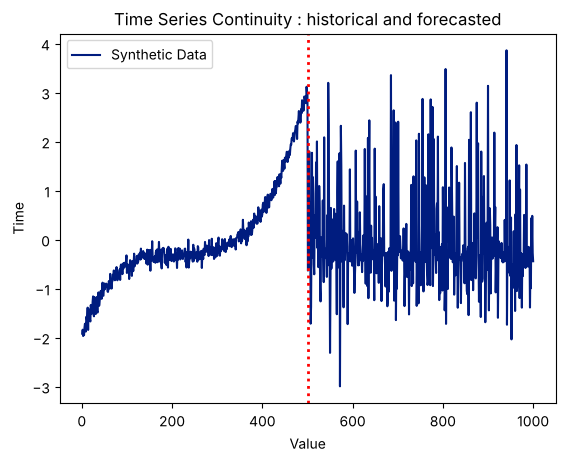

In [5]:
model.plot_series()

Real and generated series on the same axes:

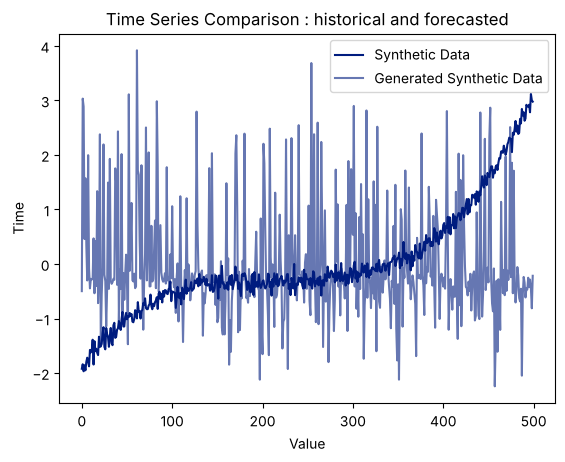

In [6]:
model.plot_compare_series()

Distribution of the values:

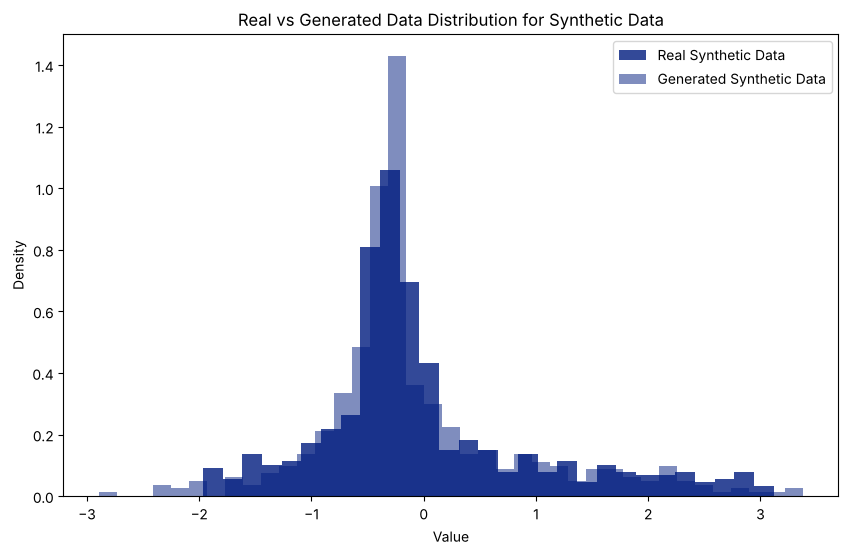

In [7]:
model.plot_histograms()

## Evaluation

Each metric is computed 20 times on the validation data, each time with newly generated samples, to get a mean and a standard deviation. Lower is better.

These values come from a single training run. GAN training varies a lot from one run to another, so they can differ from the results reported in the README, which come from the original runs.

In [8]:
n_runs = 20
metrics = {'Wasserstein': dWasserstein, 'Fréchet': dFrechet, 'ONND': ONND, 'Score': score}
values = {name: [model.compute_val_metric(f, {}) for _ in range(n_runs)] for name, f in metrics.items()}
pd.DataFrame({'mean': pd.DataFrame(values).mean(), 'std': pd.DataFrame(values).std()}).round(3)

,mean,std
Wasserstein,0.209,0.066
Fréchet,2.039,0.695
ONND,0.032,0.008
Score,3.694,1.188


## How the configuration was found

Not run here: these searches retrain the model hundreds of times and take hours. First, a Metropolis-Hastings search over architectures and hyperparameters (see `Optimisation_MH.py`):

```python
from Optimisation_MH import Metropolis_Hasting

archi = Metropolis_Hasting(0.1, data, GAN, ite=1000, metrique=score, nom_de_la_métrique="score")
```

Then a Bayesian optimisation of the hyperparameters with Optuna:

```python
model = GAN()
model.set_data(data)
model.fit_hyperparameters(
    {"lr_g": [5e-6, 5e-3], "lr_d": [5e-6, 5e-3], "epochs": [50, 150],
     "batch_size": [8, 300], "latent_dim": [1, 150]},
    n_trials=100,
)
print(model.parameters)
```